In [1]:

# Task 2: Deep Learning Project
# Step 1: Import libraries and load the MNIST dataset

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

# Load the MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Dataset loaded successfully!")


TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Dataset loaded successfully!


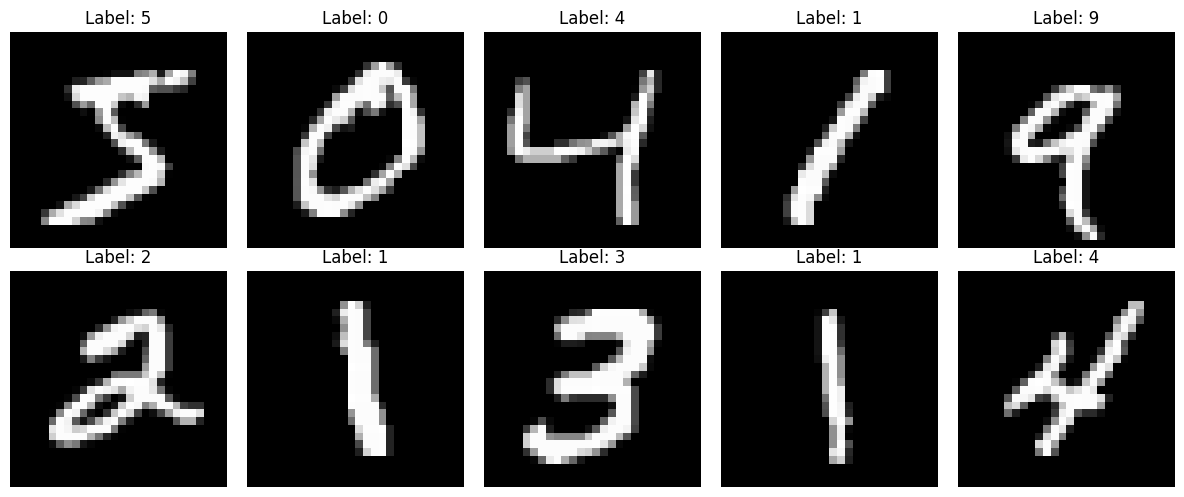

In [2]:

# STEP 2: Display sample images

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [3]:

# STEP 3: Normalize pixel values

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data preprocessing completed!")


Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data preprocessing completed!


In [4]:

# STEP 4: Build a CNN model

from tensorflow.keras import layers, models

# CNNs expect image data in height, width, channels format
x_train_cnn = x_train[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

# STEP 5: Train the CNN

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train_cnn,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")


Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.9200 - loss: 0.2629 - val_accuracy: 0.9813 - val_loss: 0.0626
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9747 - loss: 0.0815 - val_accuracy: 0.9863 - val_loss: 0.0485
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9818 - loss: 0.0602 - val_accuracy: 0.9873 - val_loss: 0.0399
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9850 - loss: 0.0477 - val_accuracy: 0.9885 - val_loss: 0.0358
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9880 - loss: 0.0389 - val_accuracy: 0.9913 - val_loss: 0.0302
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9896 - loss: 0.0332 - val_accuracy: 0.9910 - val_loss: 0.0295
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9910 - loss: 0.0277 - val_accuracy: 0.9923 - val_loss: 0.0314
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9924 - loss: 0.0240 - val_accuracy: 0.9920 -

In [6]:

# STEP 6: Evaluate on unseen test images

test_loss, test_accuracy = model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


Test loss: 0.0246
Test accuracy: 99.14%


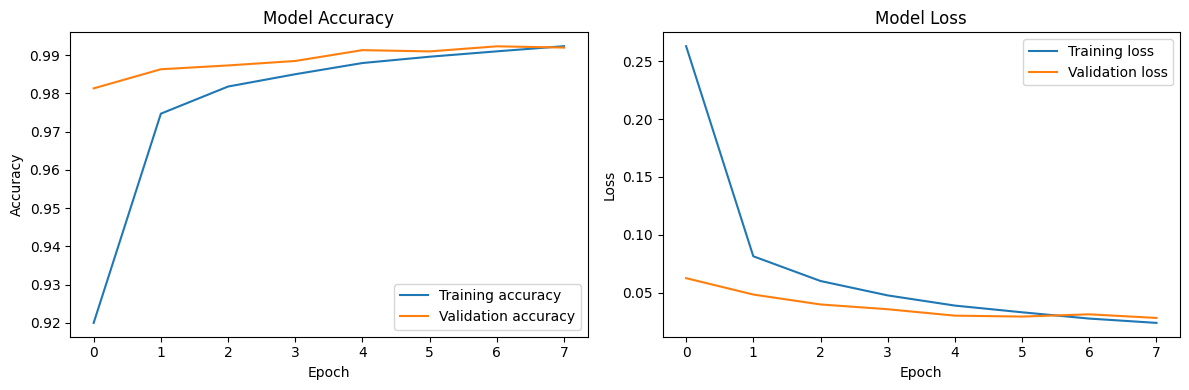

In [7]:

# STEP 7: Plot training history

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


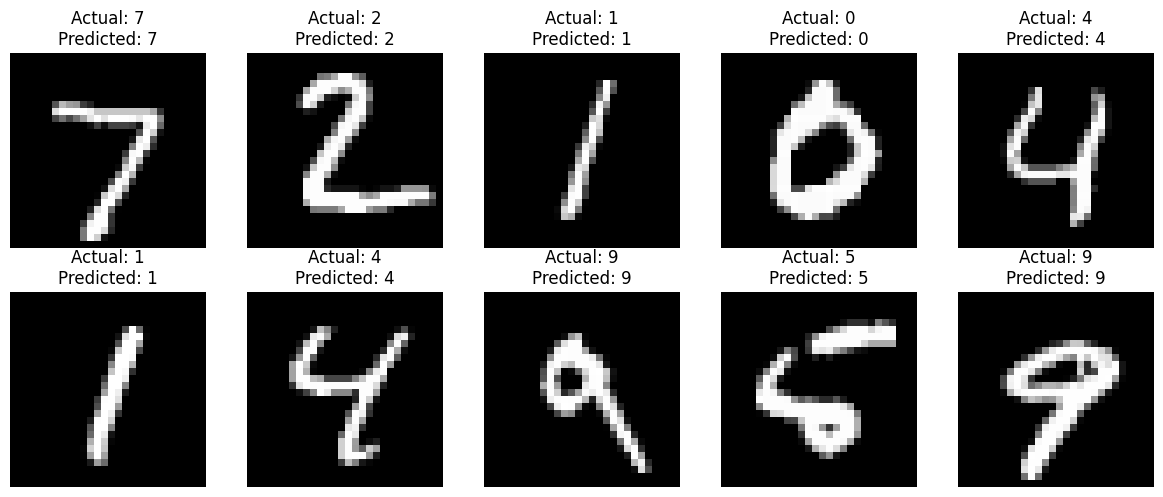

In [8]:

# STEP 8: Predict digits from test images

predicted_probabilities = model.predict(x_test_cnn[:10], verbose=0)
predicted_digits = np.argmax(predicted_probabilities, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_digits[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


Classification Report:
              precision    recall  f1-score   support

           0     0.9919    0.9969    0.9944       980
           1     0.9965    0.9947    0.9956      1135
           2     0.9961    0.9864    0.9912      1032
           3     0.9901    0.9931    0.9916      1010
           4     0.9929    0.9939    0.9934       982
           5     0.9800    0.9910    0.9855       892
           6     0.9979    0.9843    0.9911       958
           7     0.9874    0.9912    0.9893      1028
           8     0.9908    0.9908    0.9908       974
           9     0.9891    0.9911    0.9901      1009

    accuracy                         0.9914     10000
   macro avg     0.9913    0.9914    0.9913     10000
weighted avg     0.9914    0.9914    0.9914     10000



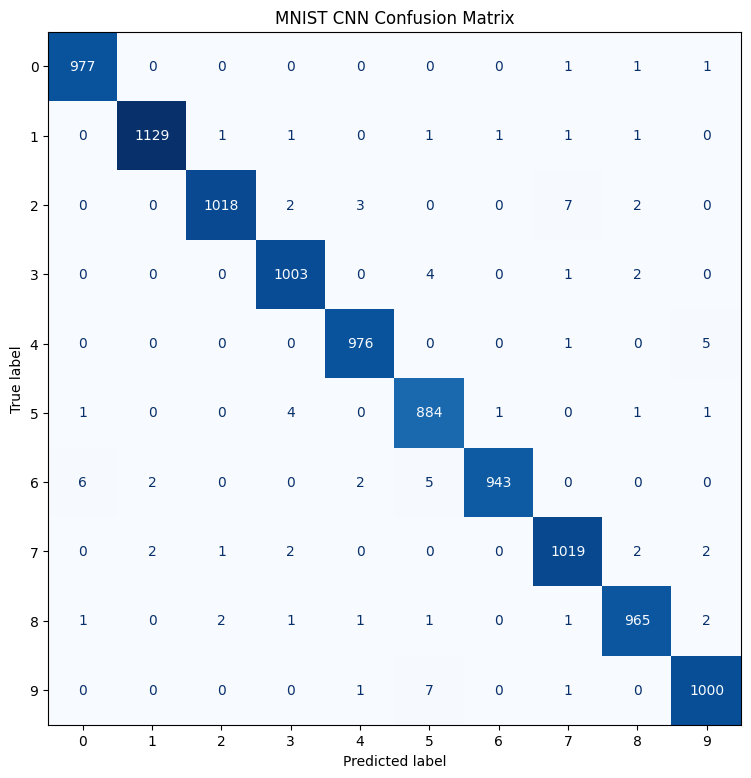

In [9]:

# STEP 9: Detailed classification evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

all_probabilities = model.predict(x_test_cnn, verbose=0)
all_predictions = np.argmax(all_probabilities, axis=1)

print("Classification Report:")
print(
    classification_report(
        y_test,
        all_predictions,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(y_test, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(cmap="Blues", ax=ax, colorbar=False)
plt.title("MNIST CNN Confusion Matrix")
plt.show()


In [10]:

# STEP 10: Save the trained model

model.save("mnist_model.keras")

print("Model saved successfully as mnist_model.keras")


Model saved successfully as mnist_model.keras


In [11]:

# STEP 11: Load and test the saved model

loaded_model = tf.keras.models.load_model("mnist_model.keras")

sample_index = 0

sample_image = x_test_cnn[sample_index:sample_index + 1]
prediction = loaded_model.predict(sample_image, verbose=0)

predicted_digit = int(np.argmax(prediction[0]))

print("Actual digit:", int(y_test[sample_index]))
print("Predicted digit:", predicted_digit)
print("Saved model loaded and tested successfully!")


Actual digit: 7
Predicted digit: 7
Saved model loaded and tested successfully!
